In [1]:
from torch.utils.data import DataLoader
%load_ext autoreload
%autoreload 2

In [2]:
import os, sys, re, random, time
import importlib, traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
import tqdm

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils import data

import data_loaders
import miscellaneous
from rs_algorithm.models import TwoTowerRecommender, ThreeTowerRecommender, InteractionHistoryRepresentation
from rs_algorithm.models import AdaptiveRepresentation, SequenceRepresentation
from rs_algorithm.models.user_models.user_02_sim import DynamicPreferenceUserModel
from dl_trainer import Trainer, split_collate, sequence_collate

In [3]:
data_model = data_loaders.KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [4]:
try:
    ds_train = data_model.get_dataset()
    smaller_matrix = miscellaneous.keyed_cache("kuairec_smaller_matrix", lambda: data_model.subsample_specimen('small', 10000))
    ds_test = data_model.get_bpr_dataset(smaller_matrix)
except:
    traceback.print_exc()

In [5]:
try:
    d_embed = 1024
    n_users, d_user_feats = data_model.user_features.shape
    n_items, d_item_feats = data_model.item_features.shape
    n_users, d_user_feats = data_model.ratings['user_id'].nunique(), data_model.user_features.shape[1]
    n_items, d_item_feats = data_model.ratings['item_id'].nunique(), data_model.item_features.shape[1]

    uid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['user_id']))}
    user_model = AdaptiveRepresentation(n_users, d_user_feats, d_hidden=1024, d_embed=d_embed, id2idx=uid2idx)
    iid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['item_id']))}
    item_model = AdaptiveRepresentation(n_items, d_item_feats, d_hidden=1024, d_embed=d_embed, id2idx=iid2idx)
    model = TwoTowerRecommender(user_model, item_model)
except:
    traceback.print_exc()

In [6]:
try:
    embed_trainer = Trainer(model=model, train_dataloader=data.DataLoader(ds_train, batch_size=8192))
except:
    traceback.print_exc()

In [7]:
try:
    embed_trainer.load_checkpoint('model_embedder_v4.1_mse_only.pt', save_backup=False)
except:
    traceback.print_exc()

In [8]:
try:
    history_model = InteractionHistoryRepresentation(
        SequenceRepresentation('attention', d_embed, d_embed),
        SequenceRepresentation('attention', 1, 1),
    )
    for mod in (user_model, item_model):
        for par in mod.parameters():
            par.requires_grad = False
    recommender = ThreeTowerRecommender(d_embed, user_model, item_model, history_model)
except:
    traceback.print_exc()

In [9]:
try:
    with torch.no_grad():
        (uid, uft, pid, pif, nid, nif), truth = next(iter(ds_test))
        uid, uft, pid, pif, nid, nif = (
            torch.tensor([uid], dtype=torch.int64), torch.tensor(uft[None, :], dtype=torch.float32),
            torch.tensor([pid], dtype=torch.int64), torch.tensor(pif[None, :], dtype=torch.float32),
            torch.tensor([nid], dtype=torch.int64), torch.tensor(nif[None, :], dtype=torch.float32))

        hid = torch.cat([nid, nid, nid], dim=0)
        hft = torch.cat([nif, nif, nif], dim=0)
        msk = torch.ones((1, 3))
        hcl = torch.ones((1, 3,))
        hcl[0, 1] = 0
        emb, *_ = recommender(uid, uft, hid, hft, hcl, msk)

        uem, ubs = user_model(uid, uft)
        pie, pib = item_model(pid, pif)
        nie, nib = item_model(nid, nif)

        print((uem * pie).mean(dim=1) + ubs + pib)
        print((uem * nie).mean(dim=1) + ubs + nib)
        print((uem * emb).mean(dim=1) + ubs)
except:
    traceback.print_exc()

Traceback (most recent call last):
  File "C:\Users\mcxiv\AppData\Local\Temp\ipykernel_4292\1582502963.py", line 14, in <module>
    emb, *_ = recommender(uid, uft, hid, hft, hcl, msk)
              ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv_cpu\Lib\site-packages\torch\nn\modules\module.py", line 1779, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv_cpu\Lib\site-packages\torch\nn\modules\module.py", line 1790, in _call_impl
    return forward_call(*args, **kwargs)
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\src\rs_algorithm\models\recommenders.py", line 67, in forward
    hist_embs, hist_bias = self.history_model(hist_embs, hist_bias, item_hist_clks, mask)
                           ~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\

In [22]:
class PretrainerDataset(data.Dataset):
    def __init__(self, data_model: 'DataModel', history_zise, length=1024, ratings=None):
        self.data_model = data_model
        self.history_size = history_zise
        self.length = length

    def __len__(self):
        return self.length

    def __getitem__(self, idx: int):
        his = self.data_model.ratings['item_id'].sample(random.randint(5, self.history_size)).to_numpy()
        hfs = self.data_model.get_item_features(his)
        with torch.no_grad():
            hem, hbs = item_model(torch.tensor(his), torch.tensor(hfs))
            hem, hbs = hem.numpy(), hbs.numpy()
        hcs = np.random.randint(0, 2, (len(his),))

        eff_hem, eff_hbs = hem[hcs == 1], hbs[hcs == 1]
        if len(eff_hem) == 0: return self.__getitem__(idx)
        wei = np.linspace(0, 2 / len(eff_hem), len(eff_hem), dtype=np.float32)
        eff_hem, eff_hbs = (eff_hem * wei[:, None]).sum(0), (eff_hbs * wei).sum(0)

        return (hem, hbs, hcs.astype(np.float32)), (eff_hem, eff_hbs)


try:
    pds = PretrainerDataset(data_model, 10, length=2048)
    for _, sample in zip(range(1), pds):
        print("sample", [y.shape for x in sample for y in x])
except:
    traceback.print_exc()

sample [(10, 1024), (10,), (10,), (1024,), ()]


In [23]:
try:
    abc = data.DataLoader(pds, batch_size=2, collate_fn=sequence_collate)
    for _, sample in zip(range(1), abc):
        print(sample[0][0].shape)
        print(sample[0][1].shape)
        print(sample[0][2].shape)
        print(sample[1][0].shape)
        print(sample[1][1].shape)
except:
    traceback.print_exc()

model_data torch.Size([2, 8])
torch.Size([2, 8, 1024])
torch.Size([2, 8])
torch.Size([2, 8])
torch.Size([2, 1024])
torch.Size([2])


In [58]:
def pre_his_loss(preds, truth):
    hem, hbs = preds
    eff_hem, eff_hbs = truth
    # print(hem.dtype, hbs.dtype, eff_hem.dtype, eff_hbs.dtype)
    return F.mse_loss(hem, eff_hem) + F.mse_loss(hbs, eff_hbs.unsqueeze(-1))


try:
    history_trainer = Trainer(
        model=recommender.history_model,
        train_dataloader=data.DataLoader(pds, batch_size=512, collate_fn=sequence_collate),
        epochs=10,
        criterion=pre_his_loss,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.000001),
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
    )
except:
    traceback.print_exc()

In [66]:
try:
    history_trainer.train()
except:
    traceback.print_exc()

Epoch:  0/10    Train Loss: 0.05    TTS: 10.35    ETA: 403.50
Epoch:  0/10    Train Loss: 0.04    TTS: 20.64    ETA: 392.20
Epoch:  0/10    Train Loss: 0.04    TTS: 30.97    ETA: 381.96
Epoch:  1/10    Train Loss: 0.04    TTS: 41.36    ETA: 372.25
Epoch:  1/10    Train Loss: 0.04    TTS: 41.36    ETA: 372.26
Epoch:  1/10    Train Loss: 0.05    TTS: 51.74    ETA: 362.18
Epoch:  1/10    Train Loss: 0.04    TTS: 62.04    ETA: 351.54
Epoch:  1/10    Train Loss: 0.04    TTS: 72.49    ETA: 341.74
Epoch:  2/10    Train Loss: 0.04    TTS: 82.85    ETA: 331.40
Epoch:  2/10    Train Loss: 0.04    TTS: 82.85    ETA: 331.40
Epoch:  2/10    Train Loss: 0.05    TTS: 93.17    ETA: 320.93
Epoch:  2/10    Train Loss: 0.04    TTS: 103.48    ETA: 310.45
Epoch:  2/10    Train Loss: 0.04    TTS: 113.66    ETA: 299.64
Epoch:  3/10    Train Loss: 0.05    TTS: 123.76    ETA: 288.77
Epoch:  3/10    Train Loss: 0.04    TTS: 123.76    ETA: 288.78
Epoch:  3/10    Train Loss: 0.05    TTS: 134.00    ETA: 278.30
Epo

dict_keys(['train', 'val', 'epoch.train', 'batch.train'])
40


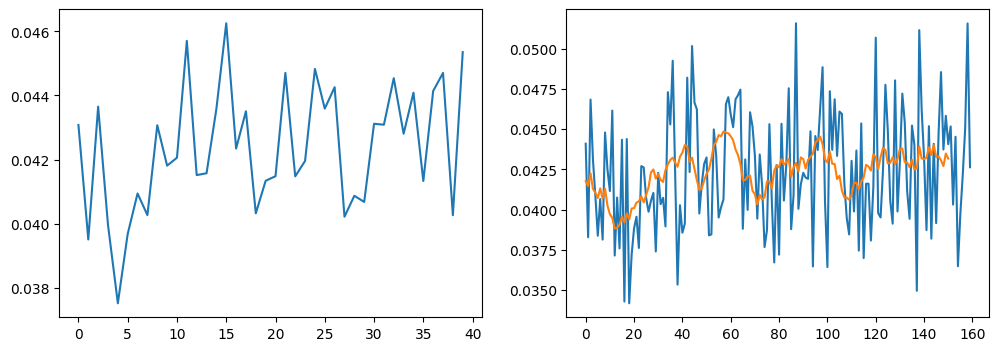

In [68]:
try:
    def running_average(arr, window=10):
        return np.convolve(arr, np.ones(window), 'valid') / window


    print(history_trainer.loss.keys())
    print(len(history_trainer.loss['epoch.train']))
    _, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].plot(history_trainer.loss['train'])
    axs[1].plot(history_trainer.loss['batch.train'])
    axs[1].plot(running_average(history_trainer.loss['batch.train']))
except:
    traceback.print_exc()

In [69]:
try:
    history_trainer.save_model("history_embeds_v1")
    history_trainer.save_loss("history_embeds_v1")
except:
    traceback.print_exc()

In [122]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def preference_function(pref, iem, ibs, ubs):
    # TODO: What would be a good way to convert it to probabilities?
    #  The raw preference calculated by the dot product ranges in -.6 to +.6 with an std of only 0.2
    #  For the time being I am using a simple hack
    print("pref", pref.min(), pref.max(), pref.std())
    print("iem", iem.min(), iem.max(), iem.std())
    print("SHAPE", pref.shape, iem.shape, (pref * iem).shape, ((pref * iem).sum()).shape)
    print("DOT", (pref * iem).min(), (pref * iem).max(), (pref * iem).std())
    dot = (pref * iem).sum()
    print("dotsum", dot.min(), dot.max(), dot.std())
    raw_relevance = (pref * iem).sum() + ubs + ibs.squeeze()
    print("raw_relevance", raw_relevance.std(), raw_relevance.min(), raw_relevance.max(), raw_relevance)
    return sigmoid(raw_relevance / 0.62 * 6)


class UserModelDataset(data.Dataset):
    def __init__(self, data_model: 'DataModel', history_zise, length=1024, ratings=None):
        self.data_model = data_model
        self.ratings: pd.DataFrame = ratings if ratings is not None else data_model.ratings
        self.ratings = self.ratings.sample(frac=1)
        self.history_size = history_zise
        self.length = length
        self.users = {}
        for uid in self.ratings['user_id'].unique():
            with torch.no_grad():
                uem, ubs = user_model(
                    torch.tensor([uid], dtype=torch.int64),
                    torch.tensor(self.data_model.get_user_features(uid)[None, :], dtype=torch.float32))
                uem, ubs = uem.numpy(), ubs.numpy().squeeze()

            self.users[uid] = DynamicPreferenceUserModel(
                preference=uem,
                preference_volatility=0.01,
                preference_function=lambda pref, iem, ibs, ubs=ubs: preference_function(pref, iem, ibs, ubs),
            )
        self.flip = True

    def __len__(self):
        # Actual length of ratings matrix is 998100
        # But data is infinite because of user model
        # So we can just iterate indefinitely
        # return len(self.ratings)
        return self.length

    def __getitem__(self, idx: int):
        idx = random.randint(0, len(self.ratings) - 1)
        user_id = self.ratings.iloc[idx]['user_id'].astype(np.int64)
        user_feats = self.data_model.get_user_features(user_id)

        subset = data_model.ratings[data_model.ratings['user_id'] == user_id]

        user = self.users[user_id]
        user.reset()

        hist_id = []
        hist_feats = []
        hist_clk = []

        for iid in subset.sample(random.randint(5, self.history_size))['item_id']:
            ift = self.data_model.get_item_features(iid)
            hist_id.append(iid), hist_feats.append(ift)
            with torch.no_grad():
                iem, ibs = item_model(
                    torch.tensor([iid], dtype=torch.int64),
                    torch.tensor(ift[None, :], dtype=torch.float32))
                clk = np.int64(user.react(None, None, iem.numpy(), ibs.numpy()))
                # print(user._relevance)
                hist_clk.append(clk)
                # print(iem.std(), user.preference.std())

        if self.flip:
            # print("flip T", end=' ')
            subset = subset[subset['rating'] > 0.75]
        else:
            # print("flip F", end=' ')
            subset = subset[subset['rating'] <= 0.75]
        for iid in subset.sample(1)['item_id']:
            ift = self.data_model.get_item_features(iid)
            with torch.no_grad():
                iem, ibs = item_model(
                    torch.tensor([iid], dtype=torch.int64),
                    torch.tensor(ift[None, :], dtype=torch.float32))
                iem, ibs = iem.numpy(), ibs.numpy()
                clk = np.int64(user.react(None, None, iem, ibs))
                print("Rel", user._relevance)

        self.flip = not self.flip

        return ((
                    user_id,
                    user_feats,
                    np.array(hist_id, dtype=np.int64),
                    np.array(hist_feats, dtype=np.float32),
                    np.array(hist_clk, dtype=np.float32),
                ), (
                    iem.flatten(),
                    ibs,
                    clk,
                ))


try:
    umd = UserModelDataset(data_model, 20, length=512)
except:
    traceback.print_exc()

### We want a balanced number of clock and non click predictions

Ideally `np.mean(clks) == 0.5`

In [114]:
try:
    pos = []
    neg = []
    clks = []
    for _, ((uid, uft, hids, hfts, hclk), (iem, ibs, clk)) in zip(tqdm.tqdm(range(len(umd))), umd):
        if umd.flip: pos.append(clk)
        else: neg.append(clk)
        clks.append(clk)
    print("Is Flip working correctly? (Expected 1.0)", len(pos) / len(neg))
    print("Is each split good? (Expected (1.0, 0.0))", np.mean(pos), np.mean(neg))
    print("Are they balanced overall? (Expected 0.5)", np.mean(clks))
except:
    traceback.print_exc()

  3%|▎         | 14/512 [00:00<00:07, 67.36it/s]

pref -2.1063285 2.0694456 0.56889343
iem -2.2242458 2.1784663 0.625864
raw_relevance 0.0 0.051223055 0.051223055 0.051223055
pref -1.4792202 1.4427482 0.44046605
iem -2.1792727 2.1641376 0.61985505
raw_relevance 0.0 118.80953 118.80953 118.80953
pref -1.1820283 1.1727254 0.4224907
iem -2.4341493 2.3914244 0.68919015
raw_relevance 0.0 223.25597 223.25597 223.25597
pref -1.5291798 1.5383351 0.47094768
iem -2.340358 2.3151433 0.6613229
raw_relevance 0.0 289.69348 289.69348 289.69348
pref -1.7725333 1.7713776 0.5166095
iem -2.1703665 2.1758149 0.6236902
raw_relevance 0.0 317.2279 317.2279 317.2279
pref -1.8918833 1.8927088 0.54402715
iem -2.2016797 2.1837726 0.62304723
raw_relevance 0.0 340.2706 340.2706 340.2706
pref -1.9848222 1.9800279 0.56551284
iem -2.2080233 2.2082458 0.62567365
raw_relevance 0.0 358.96622 358.96622 358.96622
pref -2.0517826 2.0484934 0.58238155
iem -2.2062082 2.1907952 0.625167
raw_relevance 0.0 370.8361 370.8361 370.8361
pref -2.0981102 2.091184 0.59454805
iem -2.3

  6%|▌         | 29/512 [00:00<00:06, 71.29it/s]

pref -2.2467215 2.2121131 0.6091133
iem -2.2005758 2.1576295 0.619673
raw_relevance 0.0 -0.5077777 -0.5077777 -0.5077777
pref -2.2467215 2.2121131 0.6091133
iem -2.1928663 2.1585445 0.6252705
raw_relevance 0.0 0.13724104 0.13724104 0.13724104
pref -2.2467215 2.2121131 0.6091133
iem -2.2064564 2.168678 0.6255539
raw_relevance 0.0 -0.22160769 -0.22160769 -0.22160769
pref -2.2467215 2.2121131 0.6091133
iem -2.3048544 2.2635512 0.6503828
raw_relevance 0.0 -0.03553383 -0.03553383 -0.03553383
pref -2.2467215 2.2121131 0.6091133
iem -2.1784415 2.1322913 0.61455387
raw_relevance 0.0 -0.07502157 -0.07502157 -0.07502157
pref -2.2467215 2.2121131 0.6091133
iem -2.2980978 2.2688231 0.6530299
raw_relevance 0.0 0.15275715 0.15275715 0.15275715
pref -1.5843828 1.5625598 0.4691969
iem -2.2206485 2.2080026 0.6317795
raw_relevance 0.0 126.48383 126.48383 126.48383
pref -1.2755893 1.2636608 0.4420652
iem -2.2117774 2.1872756 0.6266021
raw_relevance 0.0 208.91112 208.91112 208.91112
pref -1.5335045 1.5407

  7%|▋         | 37/512 [00:00<00:06, 69.49it/s]

pref -2.276429 2.2647614 0.61974096
iem -2.1833282 2.1919703 0.6223011
raw_relevance 0.0 -0.46870652 -0.46870652 -0.46870652
pref -2.276429 2.2647614 0.61974096
iem -2.21139 2.1631765 0.6225983
raw_relevance 0.0 -0.24056867 -0.24056867 -0.24056867
pref -2.276429 2.2647614 0.61974096
iem -2.2231917 2.1964874 0.6287306
raw_relevance 0.0 -0.2403978 -0.2403978 -0.2403978
pref -2.276429 2.2647614 0.61974096
iem -2.2234616 2.1824656 0.6278713
raw_relevance 0.0 -0.28323573 -0.28323573 -0.28323573
pref -2.276429 2.2647614 0.61974096
iem -2.2267604 2.2048829 0.6276208
raw_relevance 0.0 -0.03815408 -0.03815408 -0.03815408
pref -1.5727932 1.5865388 0.47275153
iem -2.2334304 2.1957471 0.6300773
raw_relevance 0.0 120.75287 120.75287 120.75287
pref -1.1375239 1.1153829 0.44126
iem -2.3336885 2.3187554 0.6610884
raw_relevance 0.0 216.59547 216.59547 216.59547
pref -1.4963733 1.4718621 0.4728896
iem -2.1831772 2.1680913 0.62029964
raw_relevance 0.0 268.073 268.073 268.073
pref -1.7024145 1.6807308 0.5

... (11 outputs left out)

pref -1.5905248 1.5532954 0.46585807
iem -2.343944 2.3366737 0.66628605
raw_relevance 0.0 129.74985 129.74985 129.74985
pref -1.2950629 1.1812792 0.44653374
iem -2.249206 2.2189703 0.63378215
raw_relevance 0.0 215.80193 215.80193 215.80193
pref -1.5540181 1.4925865 0.4714539
iem -2.1541595 2.1177442 0.60808045
raw_relevance 0.0 262.84 262.84 262.84
pref -1.7105211 1.6801338 0.49977592
iem -2.303283 2.3056722 0.6540437
raw_relevance 0.0 319.954 319.954 319.954
pref -1.8752213 1.8677953 0.5403109
iem -2.1849263 2.1734436 0.62017673
raw_relevance 0.0 336.5583 336.5583 336.5583
pref -1.9533697 1.9594898 0.56170714
iem -2.2320073 2.172823 0.63039196
raw_relevance 0.0 359.2733 359.2733 359.2733
pref -2.036961 2.0234897 0.58101195
iem -2.3391075 2.2946513 0.65943825
raw_relevance 0.0 391.09006 391.09006 391.09006
pref -2.127605 2.1048381 0.60382456
iem -2.178271 2.156218 0.62018335
raw_relevance 0.0 382.27756 382.27756 382.27756
pref -2.1428049 2.1202521 0.6082315
iem -2.1853986 2.1557553 0.6

 28%|██▊       | 141/512 [00:01<00:05, 70.97it/s]

pref -2.7761433 2.3632584 0.64770204
iem -2.289526 2.2741404 0.65142727
raw_relevance 0.0 0.04187858 0.04187858 0.04187858
pref -1.9395593 1.6597551 0.49372864
iem -2.4356241 2.4269824 0.6895654
raw_relevance 0.0 137.70999 137.70999 137.70999
pref -1.3524663 1.2172195 0.4678063
iem -2.4104488 2.400168 0.6876134
raw_relevance 0.0 241.5103 241.5103 241.5103
pref -1.5904057 1.5659909 0.49898368
iem -2.2846282 2.3103948 0.6539767
raw_relevance 0.0 298.27264 298.27264 298.27264
pref -1.7986724 1.7893121 0.53192765
iem -2.2030468 2.1680713 0.62659055
raw_relevance 0.0 325.3227 325.3227 325.3227
pref -1.9199847 1.9029399 0.5545909
iem -2.211523 2.1993878 0.6267341
raw_relevance 0.0 347.8266 347.8266 347.8266
pref -2.0074463 1.9918742 0.5734664
iem -2.1915135 2.1752908 0.6203845
raw_relevance 0.0 360.3042 360.3042 360.3042
pref -2.0626664 2.0468993 0.5860952
iem -2.1904056 2.1529753 0.61913663
raw_relevance 0.0 369.1155 369.1155 369.1155
pref -2.1009881 2.078722 0.5951979
iem -2.3435087 2.3006


Traceback (most recent call last):
  File "C:\Users\mcxiv\AppData\Local\Temp\ipykernel_4292\1159996785.py", line 5, in <module>
    for _, ((uid, uft, hids, hfts, hclk), (iem, ibs, clk)) in zip(tqdm.tqdm(range(len(umd))), umd):
                                                              ~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\mcxiv\AppData\Local\Temp\ipykernel_4292\1274772889.py", line 47, in __getitem__
    user_id = self.ratings.iloc[idx]['user_id'].astype(np.int64)
              ~~~~~~~~~~~~~~~~~^^^^^
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv_cpu\Lib\site-packages\pandas\core\indexing.py", line 1207, in __getitem__
    return self._getitem_axis(maybe_callable, axis=axis)
           ~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv_cpu\Lib\site-packages\pandas\core\indexing.py", line 1775, in _getitem_axis
    return self.obj._ixs(key, axis=axis)
           ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^
  File 

In [123]:
try:
    random.seed(1234)
    for _, ((uid, uft, hids, hfts, hclk), (iem, ibs, clk)) in zip(tqdm.tqdm(range(1)), umd):
        with torch.no_grad():
            uem, ubs = user_model(
                    torch.tensor([uid], dtype=torch.int64),
                    torch.tensor(uft[None, :], dtype=torch.float32))
            print("uem", uem.min(), uem.max(), uem.std())
            print("iem", iem.min(), iem.max(), iem.std())
except:
    traceback.print_exc()

100%|██████████| 1/1 [00:00<00:00, 40.27it/s]

pref -2.208092 2.1546307 0.5973508
iem -2.194298 2.1929424 0.6264529
SHAPE (1, 1024) (1, 1024) (1, 1024) ()
DOT -0.75776345 1.0820438 0.11193134
dotsum -0.19009924 -0.19009924 0.0
raw_relevance 0.0 0.24742663 0.24742663 0.24742663
pref -2.1860678 2.1330585 0.5914069
iem -2.354777 2.2986455 0.6611137
SHAPE (1, 1024) (1, 1024) (1, 1024) ()
DOT -0.7634361 1.1719395 0.115854785
dotsum 4.168447 4.168447 0.0
raw_relevance 0.0 4.3919806 4.3919806 4.3919806
pref -2.1643095 2.111929 0.58559847
iem -2.3242621 2.279542 0.65718716
SHAPE (1, 1024) (1, 1024) (1, 1024) ()
DOT -0.7101555 1.1684985 0.116132855
dotsum 8.514809 8.514809 0.0
raw_relevance 0.0 8.880461 8.880461 8.880461
pref -2.1431308 2.0907943 0.57992136
iem -2.4029706 2.3772728 0.6825334
SHAPE (1, 1024) (1, 1024) (1, 1024) ()
DOT -0.68559533 1.2436649 0.11979439
dotsum 13.426926 13.426926 0.0
raw_relevance 0.0 13.687948 13.687948 13.687948
pref -2.1217186 2.069759 0.5743882
iem -2.186208 2.1786957 0.62237275
SHAPE (1, 1024) (1, 1024) (1

In [124]:
try:
    random.seed(1234)
    for iid in data_model.ratings['item_id'].unique():
        with torch.no_grad():
            iem, ibs = item_model(
                torch.tensor([iid], dtype=torch.int64),
                torch.tensor(data_model.get_item_features(iid)[None, :], dtype=torch.float32))
            iem, ibs = iem.numpy(), ibs.numpy()
        #     clk = np.int64(user.react(None, None, iem, ibs))
        #     print("Rel", user._relevance)
except:
    traceback.print_exc()

1357
8432
3934
6264
8648
2943
9913
10259
6021
173
552
2247
693
8316
4045
768
2306
139
9299
8714
6220
530
4105
3930
2368
1622
3245
5254
10252
8646
631
255
8258
5729
2139
7029
1290
9716
7212
849
5666
3994
2609
4450
8685
3108
4211
929
5582
9848
10084
2021
1346
5615
1046
1922
5211
1399
5513
2237
10042
2131
6983
712
120
7711
5762
4213
6224
7103
5525
7777
2472
850
2065
4679
394
5738
4337
7218
670
2442
675
8557
3957
2678
10213
804
4118
4158
6898
369
3984
7078
3950
2747
152
272
3589
9833
5935
643
6094
7191
5383
2576
2049
1197
6235
2661
4112
7117
2331
683
9159
3608
7461
466
677
548
2510
669
10243
9825
7197
5659
686
2335
3739
5718
3023
4199
2460
7887
2566
4736
9987
1410
1445
3076
4050
10409
8681
7526
7775
847
5592
3089
6176
10200
5818
5510
2082
5702
8756
4185
7440
1391
2476
9886
5215
1190
2606
708
1926
5564
9103
636
8739
5670
9902
9568
570
3872
8524
7018
7704
3630
7236
4171
639
2497
8806
5783
1167
3025
1325
8538
5634
555
6879
3114
3966
7481
8664
8942
2453
5782
7635
9123
3020
7172
1337
4057
5700


In [130]:
try:
    uid = data_model.ratings['user_id'].sample(1).values[0]
    print("User", uid)
    for iid in data_model.ratings[data_model.ratings['user_id'] == uid]['item_id'].unique():
        with torch.no_grad():
            iem, ibs = item_model(
                torch.tensor([iid], dtype=torch.int64),
                torch.tensor(data_model.get_item_features(iid)[None, :], dtype=torch.float32))
            iem, ibs = iem.numpy(), ibs.numpy()
        pref = umd.users[uid]._state_vector['preference']
        thing = preference_function(pref, iem, ibs, ubs=0)
        print("THING", iid, thing)
        #     clk = np.int64(user.react(None, None, iem, ibs))
        #     print("Rel", user._relevance)
except:
    traceback.print_exc()

User 3124
pref -2.3734207 2.3309839 0.64512086
iem -2.1952157 2.1462793 0.6212185
SHAPE (1, 1024) (1, 1024) (1, 1024) ()
DOT -0.53821254 0.49733126 0.09056845
dotsum 0.57312834 0.57312834 0.0
raw_relevance 0.0 0.44566768 0.44566768 0.44566768
THING 3872 0.98678255
pref -2.3734207 2.3309839 0.64512086
iem -2.1955316 2.1650214 0.6193167
SHAPE (1, 1024) (1, 1024) (1, 1024) ()
DOT -0.54129624 0.5020022 0.09072864
dotsum 0.7120083 0.7120083 0.0
raw_relevance 0.0 0.2904195 0.2904195 0.2904195
THING 4586 0.9432412
pref -2.3734207 2.3309839 0.64512086
iem -2.287581 2.2652006 0.6474608
SHAPE (1, 1024) (1, 1024) (1, 1024) ()
DOT -0.56348747 0.5183388 0.09025877
dotsum 0.5051559 0.5051559 0.0
raw_relevance 0.0 0.53766376 0.53766376 0.53766376
THING 2461 0.9945311
pref -2.3734207 2.3309839 0.64512086
iem -2.1980488 2.164446 0.6202022
SHAPE (1, 1024) (1, 1024) (1, 1024) ()
DOT -0.54398173 0.50087446 0.08990471
dotsum 0.60804415 0.60804415 0.0
raw_relevance 0.0 0.33564895 0.33564895 0.33564895
THING

In [132]:
try:
    uid = data_model.ratings['user_id'].sample(1).values[0]
    print("User", uid)
    for iid in data_model.ratings[(data_model.ratings['user_id'] == uid) & (data_model.ratings['rating'] < 0.75)]['item_id'].unique():
        with torch.no_grad():
            iem, ibs = item_model(
                torch.tensor([iid], dtype=torch.int64),
                torch.tensor(data_model.get_item_features(iid)[None, :], dtype=torch.float32))
            iem, ibs = iem.numpy(), ibs.numpy()
        pref = umd.users[uid]._state_vector['preference']
        thing = preference_function(pref, iem, ibs, ubs=0)
        print("THING", iid, thing)
        #     clk = np.int64(user.react(None, None, iem, ibs))
        #     print("Rel", user._relevance)
except:
    traceback.print_exc()

User 4026
pref -2.343567 2.329407 0.63676685
iem -2.193742 2.1794624 0.6247268
SHAPE (1, 1024) (1, 1024) (1, 1024) ()
DOT -0.5999633 0.84850997 0.10210887
dotsum 0.0812819 0.0812819 0.0
raw_relevance 0.0 0.051873337 0.051873337 0.051873337
THING 5231 0.6229292
pref -2.343567 2.329407 0.63676685
iem -2.1712031 2.1515634 0.62020224
SHAPE (1, 1024) (1, 1024) (1, 1024) ()
DOT -0.5971561 0.83339363 0.10219294
dotsum -0.27825266 -0.27825266 0.0
raw_relevance 0.0 -0.3755535 -0.3755535 -0.3755535
THING 5436 0.025721038
pref -2.343567 2.329407 0.63676685
iem -2.3669548 2.2849224 0.66290295
SHAPE (1, 1024) (1, 1024) (1, 1024) ()
DOT -0.63807905 0.8992465 0.10684699
dotsum -0.30171412 -0.30171412 0.0
raw_relevance 0.0 -0.25052795 -0.25052795 -0.25052795
THING 5433 0.08132612
pref -2.343567 2.329407 0.63676685
iem -2.1935568 2.1704462 0.6225144
SHAPE (1, 1024) (1, 1024) (1, 1024) ()
DOT -0.59314245 0.82697225 0.10195484
dotsum -0.59319603 -0.59319603 0.0
raw_relevance 0.0 -0.21585754 -0.21585754 -

### Checking if the data even has a bias towards positive predictions

Ideally `len(pos) / len(neg) == 1`

In [185]:
try:
    subset = data_model.ratings[data_model.ratings['user_id'] == 1520]
    uft = data_model.get_user_features(1520)
    with torch.no_grad():
        uem, ubs = user_model(
            torch.tensor([1520], dtype=torch.int64),
            torch.tensor(uft[None, :], dtype=torch.float32))
    pos, neg = [], []
    for iid in subset[subset['rating'] < 0.75]['item_id']:
        ift = data_model.get_item_features(iid)
        with torch.no_grad():
            iem, ibs = item_model(
                torch.tensor([iid], dtype=torch.int64),
                torch.tensor(ift[None, :], dtype=torch.float32))
            rel = float((iem * uem).sum() + ubs + ibs)
            rel = rel / 2 + 0.5
            if random.random() < rel: pos.append(1)
            else: neg.append(1)

    print(len(pos) / len(neg))
    # print(np.mean(pos), np.mean(neg))
except:
    traceback.print_exc()

1.011049723756906


In [12]:
def bce_loss(preds, truth):
    uem, (ubs, hbs) = preds
    iem, ibs, clk = truth
    if ubs is None: ubs = 0
    rel = torch.sigmoid(((uem * iem).sum(dim=1) + ubs + ibs) / 0.62 * 6)
    return F.binary_cross_entropy(rel, clk)


def mse_loss(preds, truth):
    uem, (ubs, hbs) = preds
    iem, ibs, clk = truth
    if ubs is None: ubs = 0
    # TODO: Rfere to the same comment made in user model regarding probability conversion to understand `/ 0.62 * 6`
    rel = torch.sigmoid(((uem * iem).sum(dim=1) + ubs + ibs) / 0.62 * 6)
    # print(rel)
    return F.mse_loss(rel, clk)


def collate_fn(list_of_stuff):
    uid, uft, hid, hft, hcl = tuple(zip(*([x[0] for x in list_of_stuff])))
    uid = torch.tensor(uid)
    uft = torch.tensor(uft)
    max_seq = max(len(x) for x in hid)
    mask = torch.tensor([[i < len(x) for i in range(max_seq)] for x in hid], dtype=torch.float32)
    hid = torch.tensor([np.pad(x, (0, max_seq - len(x))) for x in hid])
    hft = torch.tensor([np.pad(x, [(0, max_seq - len(x)), (0, 0)]) for x in hft])
    hcl = torch.tensor([np.pad(x, (0, max_seq - len(x))) for x in hcl])
    iem, ibs, clk = tuple(zip(*([x[1] for x in list_of_stuff])))
    iem = torch.tensor(iem)
    ibs = torch.tensor(ibs).flatten()
    clk = torch.tensor(clk).float()
    return (uid, uft, hid, hft, hcl, mask), (iem, ibs, clk)

In [13]:
loss = None

In [19]:
try:
    trainer = Trainer(
        model=recommender,
        train_dataloader=data.DataLoader(umd, batch_size=128, collate_fn=collate_fn),
        epochs=2,
        # dataset_fraction=1,
        criterion=bce_loss,
        # criterion=mse_loss,
        # optimizer=lambda x: torch.optim.Adam(x, lr=0.001),
        optimizer=lambda x: torch.optim.SGD(x, lr=0.003),
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        loss=loss,
    )
    loss = trainer.loss
except:
    traceback.print_exc()

In [15]:
# try:
#     # trainer.load_checkpoint('checkpoint_RegressionBasedBPEModel_001_20260402_171557_0.7496953347667319.pt', save_backup=False)
#     trainer.load_checkpoint(save_backup=False)
# except:
#     traceback.print_exc()

Pick an option
  0> View All
  1> 1st Last Model checkpoint_ThreeTowerRecommender_010_20260410_125732_96.79932165145874.pt
  2> 2st Last Model checkpoint_ThreeTowerRecommender_002_20260410_125141_96.1856861114502.pt
  3> 3st Last Model checkpoint_ThreeTowerRecommender_010_20260410_124718_31.982421875.pt


In [129]:
try:
    trainer.learning_rate(0.001)
except:
    traceback.print_exc()

In [61]:
try:
    trainer.optimizer = torch.optim.SGD([
        {'params': recommender.history_model.parameters(), 'lr': 0.0000001},
        {'params': recommender.alpha.parameters(), 'lr': 0.01},
    ], lr=0.003)
    print(recommender.history_model)
except:
    traceback.print_exc()

SequenceRepresentation_attention(
  (model): AttentionRepresentation(
    (encoder): TransformerEncoderLayer(
      (self_attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=1025, out_features=1025, bias=True)
      )
      (linear1): Linear(in_features=1025, out_features=1024, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (linear2): Linear(in_features=1024, out_features=1025, bias=True)
      (norm1): LayerNorm((1025,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((1025,), eps=1e-05, elementwise_affine=True)
      (dropout1): Dropout(p=0.1, inplace=False)
      (dropout2): Dropout(p=0.1, inplace=False)
    )
    (proj): Linear(in_features=1025, out_features=1024, bias=True)
    (pool): AttentionPooling(
      (score): Linear(in_features=1024, out_features=1, bias=True)
    )
    (norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
  )
)


In [63]:
try:
    trainer.train()
    # 2 epochs, battery, 61 sec
    # 2 epochs, charge, same
except:
    traceback.print_exc()

Epoch:  0/ 2    Train Loss: 95.31    TTS: 1.91    ETA: 59.21
Epoch:  0/ 2    Train Loss: 95.31    TTS: 3.67    ETA: 55.12
Epoch:  0/ 2    Train Loss: 97.66    TTS: 5.52    ETA: 53.39
Epoch:  0/ 2    Train Loss: 95.21    TTS: 7.31    ETA: 51.17
Epoch:  0/ 2    Train Loss: 98.44    TTS: 9.13    ETA: 49.32
Epoch:  0/ 2    Train Loss: 96.88    TTS: 10.94    ETA: 47.41
Epoch:  0/ 2    Train Loss: 96.78    TTS: 12.74    ETA: 45.49
Epoch:  0/ 2    Train Loss: 99.11    TTS: 14.49    ETA: 43.47
Epoch:  0/ 2    Train Loss: 98.44    TTS: 16.28    ETA: 41.60
Epoch:  0/ 2    Train Loss: 96.09    TTS: 18.05    ETA: 39.70
Epoch:  0/ 2    Train Loss: 96.09    TTS: 19.79    ETA: 37.78
Epoch:  0/ 2    Train Loss: 95.31    TTS: 21.59    ETA: 35.98
Epoch:  0/ 2    Train Loss: 98.44    TTS: 23.36    ETA: 34.14
Epoch:  0/ 2    Train Loss: 99.22    TTS: 25.18    ETA: 32.37
Epoch:  0/ 2    Train Loss: 93.75    TTS: 26.98    ETA: 30.57
Epoch:  1/ 2    Train Loss: 96.88    TTS: 28.77    ETA: 28.77
Epoch:  1/ 2 

dict_keys(['train', 'val', 'epoch.train', 'batch.train'])
12


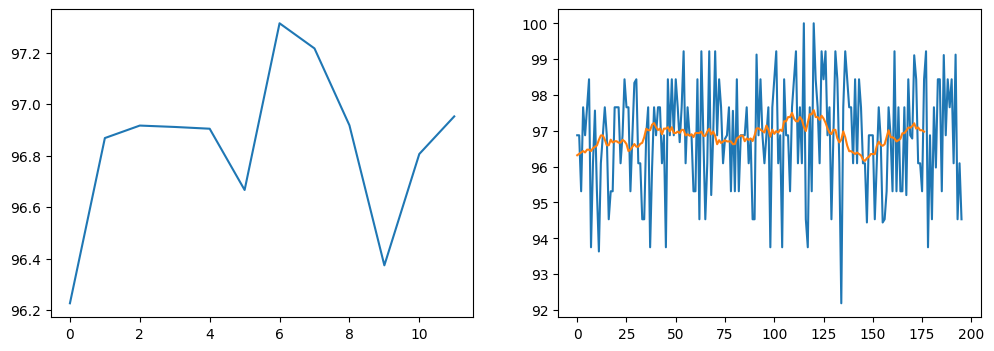

In [64]:
try:
    def running_average(arr, window=20):
        return np.convolve(arr, np.ones(window), 'valid') / window


    print(trainer.loss.keys())
    print(len(trainer.loss['epoch.train']))
    _, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].plot(trainer.loss['train'])
    axs[1].plot(trainer.loss['batch.train'])
    axs[1].plot(running_average(trainer.loss['batch.train']))
except:
    traceback.print_exc()

In [58]:
try:
    with torch.no_grad():
        (uid, uft, hid, hft, hcl, msk), (iem, ibs, clk) = next(iter(data.DataLoader(umd, collate_fn=collate_fn)))

        uem, ubs = user_model(uid, uft)
        print("Without History", (uem * iem).sum() + ubs + ibs)

        pref = torch.tensor(umd.users[uid.item()].preference)
        print("Actual Preference", (pref * iem).sum() + ubs + ibs)
        print("Click", clk)

        pref = torch.tensor(umd.users[uid.item()]._state_vector['preference'])
        print("Original Preference", (pref * iem).sum() + ubs + ibs)

        alpha = recommender.alpha(uem)
        print('history weight', 1 - alpha)

        uem2, (ubs2, _) = recommender(uid, uft, hid, hft, hcl, msk)
        print("With History", (uem2 * iem).sum() + ubs2 + ibs)
except:
    traceback.print_exc()

Without History tensor([0.0724])
Actual Preference tensor([388.9958])
Click tensor([1.])
Original Preference tensor([0.1163])
history weight tensor([[0.3734]])
With History tensor([-11.0597])


In [109]:
try:
    print(len(trainer.loss['batch.train']))
    # trainer.loss['batch.train'] = trainer.loss['batch.train'][5:]
except:
    traceback.print_exc()

34


In [227]:
try:
    trainer.save_model("recommender_v2")
    trainer.save_loss("recommender_v2")
except:
    traceback.print_exc()